# Walkthrough: racing a World Cup Giant Slalom on the real Gran Risa

*Kyle Robin and Liam Baron, DCS 340 Evolutionary Computing, Bates College*

This notebook is a guided tour of the project for someone who has taken an intro programming course but not evolutionary computing. It runs top to bottom in a few minutes on a laptop.

**The question.** In a Giant Slalom (GS), a racer goes through a set of gates as fast as possible. The *line* (the path they take between the gates) decides the race:
- a short, straight line needs tight turns, and tight turns scrub off speed;
- a round line keeps speed but travels further;
- a line that's too aggressive risks a crash or a missed gate, a "DNF" (did not finish).

We want the line that is fastest **on average**, counting the chance of a DNF, on the real slope of the Gran Risa in Alta Badia, Italy, where the World Cup races every December.

**The idea from this course.** We let *evolution* search for that line: generate many candidate lines, keep the fastest, mutate and recombine them, and repeat. We compare that against gradient descent (the method used to train neural networks) and a classic grid search.

In [1]:
import sys; sys.path.insert(0, "..")   # run from notebooks/: make the skiopt package importable
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Video, display

from skiopt import terrain3d as T
from skiopt.course3d import build_gran_risa

## 1. The mountain

The terrain is a real elevation model from the province of South Tyrol: one height every 2.5 m. The piste outline comes from OpenStreetMap. Below we load the model and check it against the published course facts (448 m vertical drop, about 1.25 km long).

grid: 1040 x 640 cells of 2.5 m, heights 1382-2083 m


course: 1146 m along the centreline (horizontal), from 1868 m down to 1420 m (drop 448 m; published: 448 m)


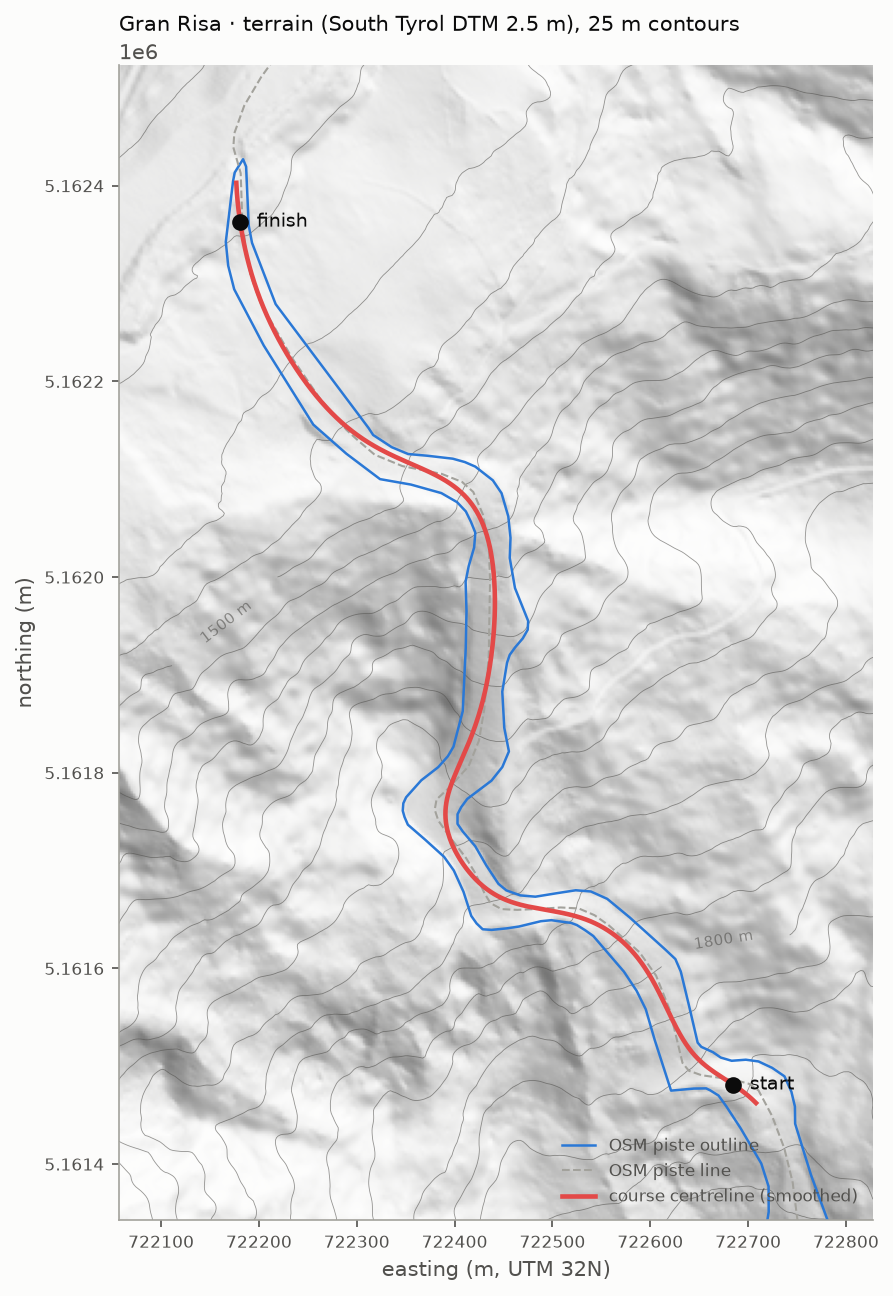

In [2]:
hf = T.HeightField.load(T.DATA / "gran_risa" / "terrain.npz")
print(f"grid: {hf.z.shape[0]} x {hf.z.shape[1]} cells of {hf.cell} m, heights {hf.z.min():.0f}-{hf.z.max():.0f} m")

build = build_gran_risa(seed=0)          # the course frame, the piste edges and the FIS gate set
f = build.frame
length = float(build.spec.length)
z_start, z_finish = hf.height(*f.to_map(0.0, 0.0)), hf.height(*f.to_map(length, 0.0))
print(f"course: {length:.0f} m along the centreline (horizontal), from {z_start:.0f} m down to {z_finish:.0f} m "
      f"(drop {z_start - z_finish:.0f} m; published: 448 m)")
display(Image("../docs/reports/gran_risa_terrain/map.png", width=420))

## 2. The course

Real gate positions are never published, so the project's course generator sets a **FIS-legal** course on the real slope. FIS is the international ski federation, and its rules fix things like the gate spacing and how far the course may swing side to side. The generator uses the same number of gates as the 21 December 2025 race (52), so the course matches that race's rhythm.

In [3]:
spec = build.spec
print(f"{spec.n_gates} gates; colours alternate: {list(spec.gate_colour[:6])} ...")
race = json.loads((T.DATA / "gran_risa" / "race_2025_run1.json").read_text())
print("real race, run 1:", race["fastest_run1"]["athlete"], "-", race["fastest_run1"]["finish_s"], "s")

52 gates; colours alternate: ['blue', 'red', 'blue', 'red', 'blue', 'red'] ...
real race, run 1: SCHWARZ Marco (AUT), bib 1 - 76.0 s


## 3. What the optimizer actually changes

A line is described by a short list of numbers, two per gate: **how far outside the gate pole the skier passes**, and **where along the turn the apex (the closest point) sits**. Between gates, the line is circular arcs. With 52 gates that is about 100 numbers. Each optimizer searches over this list, the line's "genome" in the language of this course.

To score a line, the **simulator** runs a skier down it on the 3D surface, step by step:
- gravity, snow friction and air drag set the speed;
- turning costs speed (carving loss);
- the slope's tilt and its rolls and compressions change the load on the skier;
- the edge angle can't exceed the point where the boot touches the snow ("boot-out").

The score is the **expected race time**:

> E[score] = P(finish) × time + P(DNF) × a big penalty time

P(DNF) comes from a risk model: hard turns at high G, very tight radii, being late into a gate, or nearly stopping all raise it.

## 4. Run evolution ourselves (small budget)

The real experiments give each method 200,000 simulated runs and repeat each one 10 times. Here we run a mini version:
- the **coach line**, a sensible hand-made line that doesn't search at all;
- **CMA-ES**, an evolution strategy, with only 3,200 simulated runs.

CMA-ES keeps a *distribution* of candidate lines (a mean and a spread). Each generation it samples 32 lines, ranks them by score, and moves the distribution toward the best ones. It also learns which directions in the 100-number space are worth exploring.

In [4]:
import yaml, tempfile, pathlib
from skiopt.run import run_experiment
from skiopt.analysis.summarize import load_runs

tmp = pathlib.Path(tempfile.mkdtemp())
exp = {"experiment": "notebook", "course": {"kind": "gran_risa", "seed": 0}, "policy": "arc",
       "methods": [{"name": "coach_line"},
                   {"name": "cmaes", "population": 32, "sigma": 0.5, "budget": 3200}],
       "seeds": [0]}
(tmp / "nb.yaml").write_text(yaml.safe_dump(exp))
run_experiment(tmp / "nb.yaml", results_dir=str(tmp / "results"))

runs = {r["method"]["name"]: r for r in load_runs(tmp / "results" / "notebook")}
for name, r in runs.items():
    print(f"{name:11s} time {r['T']:.2f} s   chance of DNF {100 * r['P_DNF']:.1f}%")

done  coach_line       seed 0  T=94.895 s  v_mean=50.6 km/h  missed=0  P_DNF=12.0%  evals=1  2.0 s


done  cmaes            seed 0  T=76.692 s  v_mean=61.8 km/h  missed=0  P_DNF=1.1%  evals=3200  5.5 s
cmaes       time 76.69 s   chance of DNF 1.1%
coach_line  time 94.89 s   chance of DNF 12.0%


Even with a tiny budget, evolution beats the hand-made line by many seconds. The progress log shows how the best score improved generation by generation:

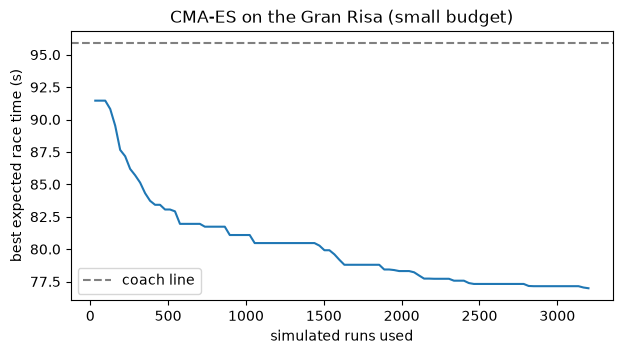

In [5]:
prog = pd.DataFrame(runs["cmaes"]["_progress"])[["evals", "best"]].astype(float)
plt.figure(figsize=(7, 3.5))
plt.plot(prog["evals"], prog["best"])
plt.axhline(runs["coach_line"]["best_score"], ls="--", color="grey", label="coach line")
plt.xlabel("simulated runs used"); plt.ylabel("best expected race time (s)")
plt.title("CMA-ES on the Gran Risa (small budget)"); plt.legend()
display(plt.gcf()); plt.close()

Here is that CMA-ES line on the map. The colour is speed: darker means faster.

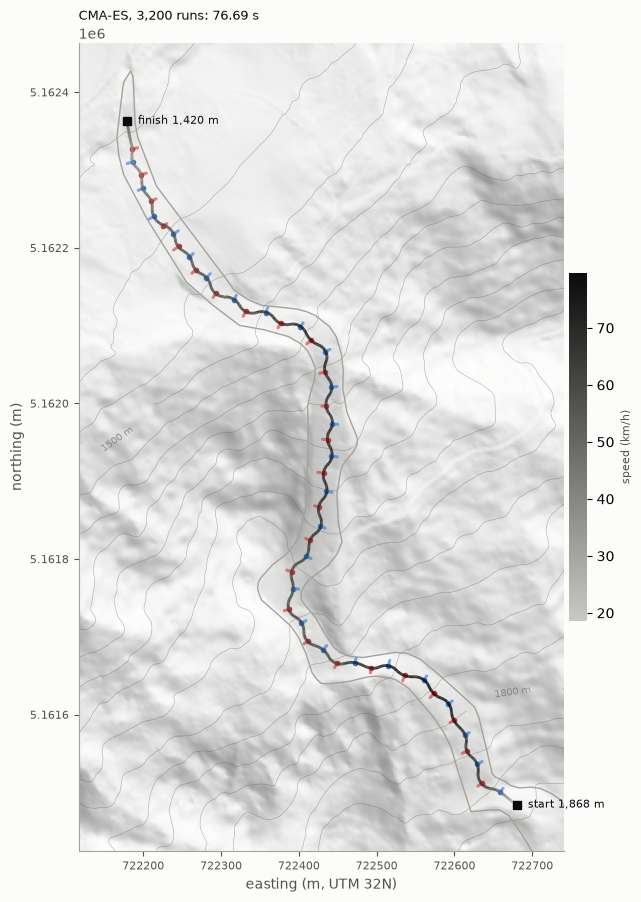

In [6]:
from skiopt.analysis.gran_risa_figures import line_on_map, _telemetry
fig = line_on_map(build, _telemetry(runs["cmaes"]["_dir"]), f"CMA-ES, 3,200 runs: {runs['cmaes']['T']:.2f} s")
display(fig); plt.close(fig)

## 5. The full experiment

The final experiment (`configs/experiments/gran_risa.yaml`) gives every method the same budget of 200,000 simulated runs and repeats each one with 10 random seeds. The table summarizes the saved results; the full report is in `docs/reports/final_gran_risa/SUMMARY.md`.

In [7]:
df = pd.read_csv("../docs/reports/final_gran_risa/summary.csv")
table = (df.groupby("method")
           .agg(best_time=("T", "min"), mean_time=("T", "mean"), spread=("T", "std"), wall_clock_s=("wall_clock_s", "mean"))
           .sort_values("mean_time").round(2))
table

,best_time,mean_time,spread,wall_clock_s
method,,,,
cmaes,74.42,74.51,0.06,151.68
hybrid,74.47,74.59,0.10,2519.13
ga,74.70,74.82,0.07,80.76
dp,75.94,75.94,0.00,51.23
dp_adam,75.94,75.94,0.00,3418.99
cmaes_smooth,76.34,77.06,0.47,149.93
adam,76.86,77.35,0.25,3584.67
coach_line,94.89,94.89,0.00,2.30


How to read it:
- **CMA-ES**, and the hybrid that starts with CMA-ES, are fastest. Both beat the real winner's 76.00 s, and both beat the **DP grid search**, because evolution can place apexes between grid points.
- **Adam** (gradient descent) is slower. It needs a smoothed version of the score, and the report (§6) traces most of its gap to a bias in that smoothing.
- The spread across seeds is tiny for CMA-ES. It finds the same answer from different random starts.

## 6. Watch the race

Every method's best line raced head to head on the 3D Gran Risa, filmed like a TV broadcast (`skiopt/analysis/race_video.py`):

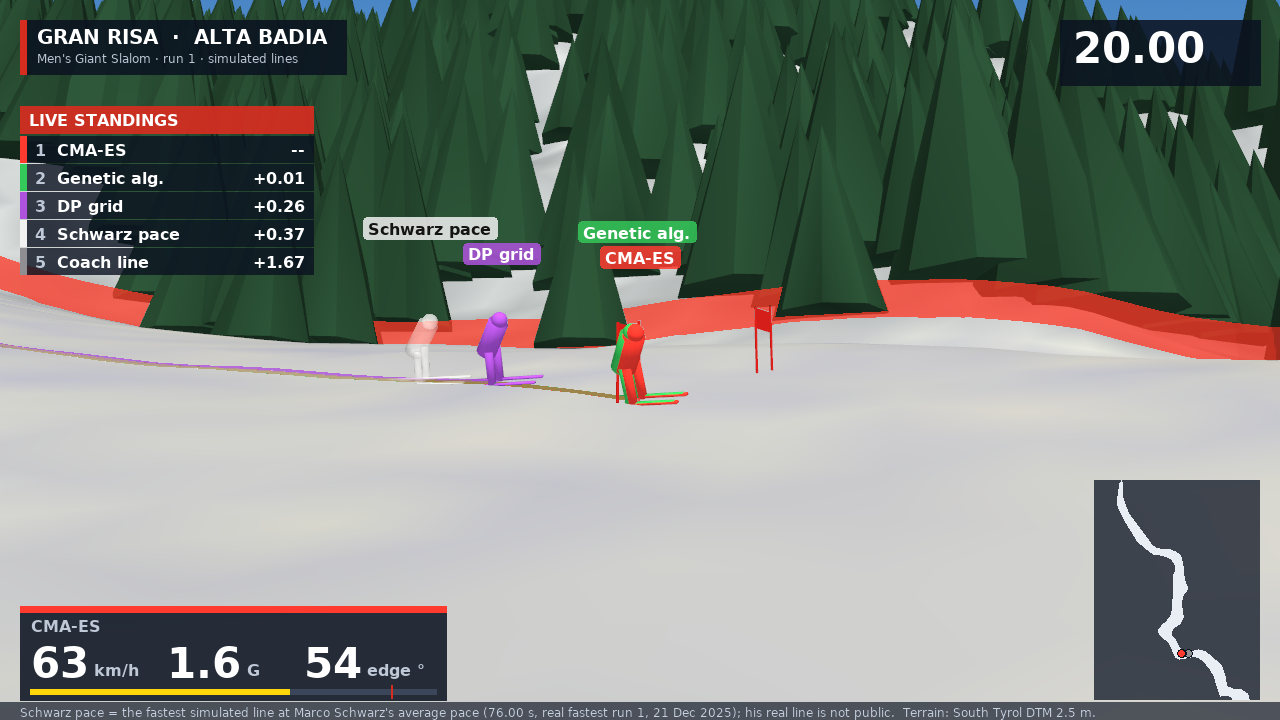

Full video: docs/media/gran_risa_race.mp4


In [8]:
display(Image("../docs/media/gran_risa_race_poster.png", width=800))
print("Full video: docs/media/gran_risa_race.mp4")

## Where to look in the code

| If you want to see... | Open |
| --- | --- |
| the physics of one step down the hill | `skiopt/sim3d.py` |
| how a line becomes a path (arcs between gate apexes) | `skiopt/policies.py` |
| the score and the DNF risk | `skiopt/objectives.py`, `skiopt/hazard.py`, `configs/risk.yaml` |
| our genetic algorithm and CMA-ES | `skiopt/optim/evo.py` |
| gradient descent, the hybrid and the grid search | `skiopt/optim/gradient.py`, `hybrid.py`, `dp.py` |
| the full write-up | `docs/REPORT.md` |